# 06 · Model Karşılaştırma Sonuçları

**Amaç:** `03_train_baseline` ve `05_train_comparison` defterlerinin Drive'a kaydettiği `results.json` ve `history.json` dosyalarını okuyup tek tabloda ve grafiklerde karşılaştırmak.

* Bu defter **eğitim yapmaz** ve **GPU gerektirmez**; veri setini belleğe yüklemez.
* 2. kod hücresindeki `HIZLI_MOD` ayarıyla:
  * `HIZLI_MOD = False` *(nihai rapor)*: sadece tam eğitimleri (`2015, 2017, 2019`) okur, `_hizli` klasörlerini dışarıda bırakır.
  * `HIZLI_MOD = True` *(ön izleme)*: sadece `_hizli` denemelerini (`2017`) okuyup kendi aralarında karşılaştırır.
* Üretilen tablo ve şekiller `results/` klasörüne kaydedilir.

In [1]:
# --- Kurulum: hem Google Colab'da hem kendi bilgisayarında çalışır ---
import json, os, sys
from pathlib import Path

BOOTSTRAP_BRANCH = os.environ.get("TORNADO_BRANCH", "m")

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive, userdata
    drive.mount("/content/drive")                     # işlenmiş veri ve modeller Drive'da saklanır
    REPO = Path("/content/tornado-cnn")
    cfg_file = REPO / "configs" / "experiments.json"
    branch = json.loads(cfg_file.read_text())["repo"]["branch"] if cfg_file.exists() else BOOTSTRAP_BRANCH
    if not REPO.exists():
        try:                                          # repo private ise: Colab Secrets'taki token
            token = userdata.get("GITHUB_TOKEN") + "@"
        except Exception:                             # repo public ise token gerekmez
            token = ""
        !git clone -q -b {branch} https://{token}github.com/baevv/tornado-cnn.git {REPO}
    else:
        !git -C {REPO} fetch -q origin {branch}
        !git -C {REPO} checkout -q {branch}
        !git -C {REPO} pull -q origin {branch}
    os.chdir(REPO)
else:
    REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    cfg_file = REPO / "configs" / "experiments.json"
    branch = json.loads(cfg_file.read_text())["repo"]["branch"] if cfg_file.exists() else BOOTSTRAP_BRANCH

sys.path.insert(0, str(REPO))
for _m in [m for m in sys.modules if m == "src" or m.startswith("src.")]:
    del sys.modules[_m]

print("Colab" if IN_COLAB else "Yerel", "| repo:", REPO, "| dal:", branch)

Mounted at /content/drive
Colab | repo: /content/tornado-cnn | dal: m


In [2]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src.helper import paths

HIZLI_MOD = True   # True: _hizli (2017) denemelerini göster | False: sadece tam eğitimler (nihai)

try:
    data_root, primary_models = paths.prepare_colab_dirs()
    SEARCH_ROOTS = list(dict.fromkeys([primary_models, data_root.parent / "models"]))
except FileNotFoundError:
    SEARCH_ROOTS = [paths.models_root()]

RESULTS_DIR = REPO / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
SUFFIX = "_hizli" if HIZLI_MOD else ""

exp_registry = paths.load_config("experiments.json")
EXPERIMENTS = {}
for item in (exp_registry.get("baselines", []) + exp_registry.get("experiments", [])):
    key = f"{item['name']}_hizli" if HIZLI_MOD else item["name"]
    lbl = f"{item['label']} [hızlı]" if HIZLI_MOD else item["label"]
    EXPERIMENTS[key] = lbl

import re


def seed_group(folder: str):
    """"03_baseline_s7_hizli" → ("03_baseline_hizli", 7); seed eki yoksa (klasör, None). Karar M3."""
    m = re.match(r"^(.*)_s(\d+)(_hizli)?$", folder)
    return (m.group(1) + (m.group(3) or ""), int(m.group(2))) if m else (folder, None)


def seed_label(folder: str) -> str:
    """Ek seed klasörüne okunur ad: deneyin etiketi + " · seed 7"."""
    base, seed = seed_group(folder)
    return f"{EXPERIMENTS.get(base, base)} · seed {seed}" if seed is not None else folder


# Eşleşen ek klasörleri otomatik ekle (HIZLI_MOD=False iken _hizli asla alınmaz)
for root in SEARCH_ROOTS:
    if root.exists():
        for d in sorted(root.iterdir()):
            if not d.is_dir():
                continue
            if HIZLI_MOD:
                if d.name.endswith("_hizli") and d.name not in EXPERIMENTS:
                    EXPERIMENTS[d.name] = seed_label(d.name)
            else:
                if d.name.startswith(("03_", "05_")) and "_hizli" not in d.name and d.name not in EXPERIMENTS:
                    EXPERIMENTS[d.name] = seed_label(d.name)

def find_model_dir(folder: str):
    for root in SEARCH_ROOTS:
        if (root / folder / "results.json").exists():
            return root / folder
    return None

found, missing = [], []
for folder, label in EXPERIMENTS.items():
    if not HIZLI_MOD and "_hizli" in folder:
        continue
    if HIZLI_MOD and not folder.endswith("_hizli"):
        continue
    mdir = find_model_dir(folder)
    if mdir is not None:
        found.append((folder, label, mdir))
    else:
        missing.append(folder)

print("Mod:", "HIZLI (_hizli, 2017)" if HIZLI_MOD else "TAM EĞİTİM")
print("Aranan model klasörleri:", SEARCH_ROOTS)
print("Bulunanlar:", [f for f, _, _ in found])
if missing:
    print("Henüz eğitilmemiş (atlandı):", missing)

Mod: HIZLI (_hizli, 2017)
Aranan model klasörleri: [PosixPath('/content/drive/MyDrive/tornado-cnn/models')]
Bulunanlar: ['05_cnn_avg_hizli', '05_resnet18_pretrained_hizli', '05_resnet18_scratch_hizli', '05_cnn_bn_hizli']
Henüz eğitilmemiş (atlandı): ['03_baseline_hizli', '03_mit_hizli']


## 1. Karşılaştırma tablosu

* Dengesiz hortum verisinde doğruluk (`doğruluk`) tek başına yanıltıcı olduğundan tablo ana ölçüt olan **`PR-AUC`** değerine göre azalan sırada listelenir.
* `PR-AUC` ve `ROC-AUC` eşikten bağımsızdır. `F1`, `Recall` ve `Precision` ise doğrulama kümesinde seçilen eşikle hesaplandığından hafifçe iyimser olabilir; nihai tarafsız değerlendirmede bu eşik test kümesinde sabit tutulacaktır.

In [3]:
# Eski 03_* kayıtlarında `params` alanı yoksa TornadoCNN parametre sayısını doğrudan hesapla
def fallback_params(folder: str):
    if folder.startswith("03_"):
        try:
            from src.helper.model import TornadoCNN, count_params
            return count_params(TornadoCNN())
        except ImportError:
            return 105761
    return None

rows = []
histories = {}
best_eps = {}   # results.json'daki en iyi tur (her model kendi izlediği ölçüte göre seçti)
for folder, default_label, mdir in found:
    with open(mdir / "results.json", encoding="utf-8") as f:
        res = json.load(f)
    h_path = mdir / "history.json"
    hist = pd.read_json(h_path) if h_path.exists() else pd.DataFrame()
    if not hist.empty:
        histories[folder] = (default_label, hist)

    cfg_i = res.get("config", {})
    val = res.get("validation", {})
    best_ep = res.get("best_epoch")
    best_eps[folder] = best_ep
    val_loss = res.get("val_loss")
    if val_loss is None and not hist.empty and best_ep is not None:
        hit = hist.loc[hist["tur"] == best_ep, "doğrulama kaybı"]
        val_loss = float(hit.iloc[0]) if not hit.empty else None

    rows.append({
        "Klasör": folder,
        "Model": default_label,
        "Yıllar": ",".join(map(str, res.get("years", []))),
        "Ağırlık": cfg_i.get("weighting", "-"),
        "Parametre": res.get("params") or fallback_params(folder),
        "lr": cfg_i.get("lr"),
        "En İyi Tur": best_ep,
        "Toplam Tur": int(hist["tur"].max()) if not hist.empty else None,
        "Doğrulama Kaybı": val_loss,
        "PR-AUC": val.get("PR-AUC"),
        "ROC-AUC": val.get("ROC-AUC"),
        "F1": val.get("F1"),
        "Recall": val.get("recall (yakalama)"),
        "Precision": val.get("precision (isabet)"),
        "Doğruluk": val.get("doğruluk"),
        "Eşik": res.get("threshold"),
    })

table = pd.DataFrame(rows).sort_values("PR-AUC", ascending=False).reset_index(drop=True) if rows else pd.DataFrame()
if not table.empty:
    table.to_csv(RESULTS_DIR / f"model_comparison{SUFFIX}.csv", index=False)

print("Not — Flatten kullanılsaydı: 128 × 7 × 15 = 13.440 özellik → Linear(13440, 64) = 860.224 parametre "
      "(toplam 957.729; mevcut Global Max/Avg TornadoCNN ise 105.761 parametre).")
table.round({"Doğrulama Kaybı": 4, "PR-AUC": 4, "ROC-AUC": 4, "F1": 4, "Recall": 4, "Precision": 4, "Doğruluk": 4, "Eşik": 3}) if not table.empty else table

Not — Flatten kullanılsaydı: 128 × 7 × 15 = 13.440 özellik → Linear(13440, 64) = 860.224 parametre (toplam 957.729; mevcut Global Max/Avg TornadoCNN ise 105.761 parametre).


,Klasör,Model,Yıllar,Ağırlık,Parametre,lr,En İyi Tur,Toplam Tur,Doğrulama Kaybı,PR-AUC,ROC-AUC,F1,Recall,Precision,Doğruluk,Eşik
0,05_cnn_bn_hizli,TornadoCNN (Global Max + BN) [hızlı],2017,pos_weight,106241,0.0010,7,11,0.8451,0.5149,0.8710,0.5185,0.4840,0.5583,0.9350,0.874
1,05_resnet18_pretrained_hizli,ResNet-18 (ön-eğitimli) [hızlı],2017,pos_weight,11177025,0.0001,9,13,2.3400,0.4484,0.8221,0.4552,0.4734,0.4384,0.9181,0.291
2,05_cnn_avg_hizli,TornadoCNN (Global Avg) [hızlı],2017,pos_weight,105761,0.0010,16,20,0.8632,0.3876,0.8546,0.4658,0.4521,0.4802,0.9251,0.744
3,05_resnet18_scratch_hizli,ResNet-18 (sıfırdan) [hızlı],2017,pos_weight,11177025,0.0001,7,11,1.8454,0.2668,0.7657,0.3191,0.3777,0.2763,0.8836,0.979


### Seed'ler arası değişkenlik (karar M3)

Ana karşılaştırmanın iki modeli (TornadoCNN temel ve ResNet-18 ön-eğitimli) 3 seed ile eğitildi (`<ad>`, `<ad>_s7`, `<ad>_s123`). Tablo, birden fazla seed'i olan her deney için ortalama ± std verir.

**Nasıl okunur:** Temel modelin PR-AUC std'si **gürültü ölçüsüdür**. Tek seed ile eğitilen bir ablasyonun temel modele farkı bu std'den küçükse, fark yorumlanmaz.

In [ ]:
if not table.empty:
    t = table.assign(Deney=[seed_group(f)[0] for f in table["Klasör"]])
    counts = t.groupby("Deney").size()
    multi = counts[counts >= 2].index
    if len(multi):
        cols = ["PR-AUC", "ROC-AUC", "F1", "Eşik", "En İyi Tur"]
        g = t[t["Deney"].isin(multi)].groupby("Deney")[cols]
        seed_table = g.mean().round(4).astype(str) + " ± " + g.std().round(4).astype(str)
        seed_table.insert(0, "seed sayısı", counts[multi])
        seed_table.to_csv(RESULTS_DIR / f"seed_summary{SUFFIX}.csv")
        display(seed_table)
        base = next((d for d in multi if d.startswith("03_baseline")), None)
        if base is not None:
            noise = float(t.loc[t["Deney"] == base, "PR-AUC"].std())
            print(f"Gürültü ölçüsü (temel modelin PR-AUC std'si): {noise:.4f}. "
                  "Ablasyonların temel modele farkı bundan küçükse yorumlanmaz.")
    else:
        print("Henüz birden fazla seed ile eğitilmiş deney yok (05 defteri, 8. bölüm).")

## 2. Öğrenme eğrileri

Üstteki grafiklerde her modelin **eğitim ve doğrulama kaybı** kendi ölçeğinde (farklı `pos_weight` değerleri kayıp ölçeğini değiştirdiği için ayrı eksenlerde), alttaki iki grafikte ise modellerin **doğrulama PR-AUC ve ROC-AUC** gidişatı ortak eksende gösterilir.

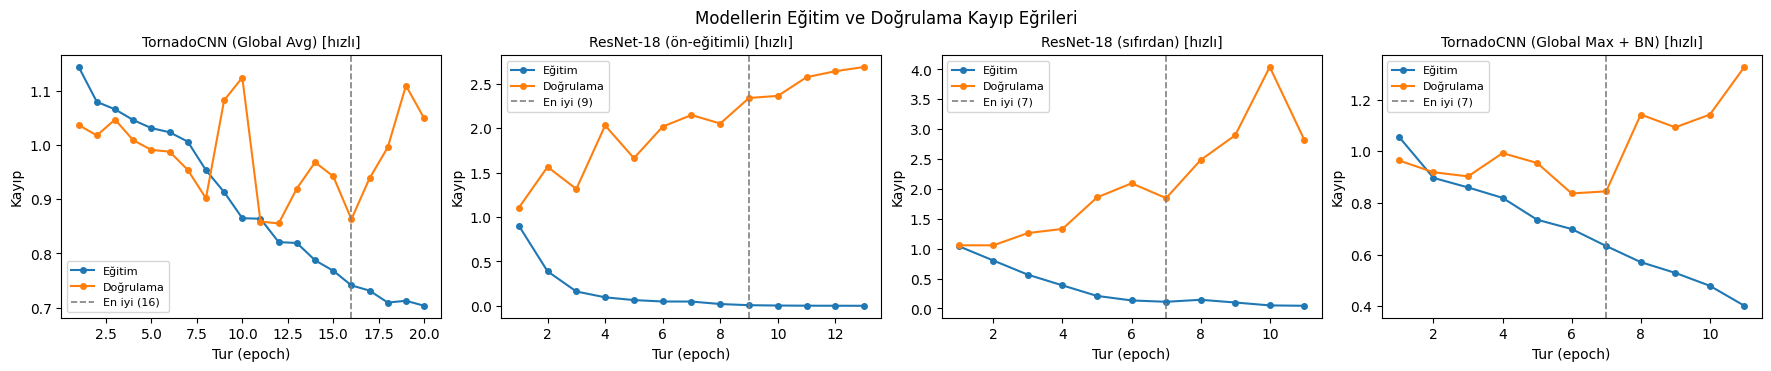

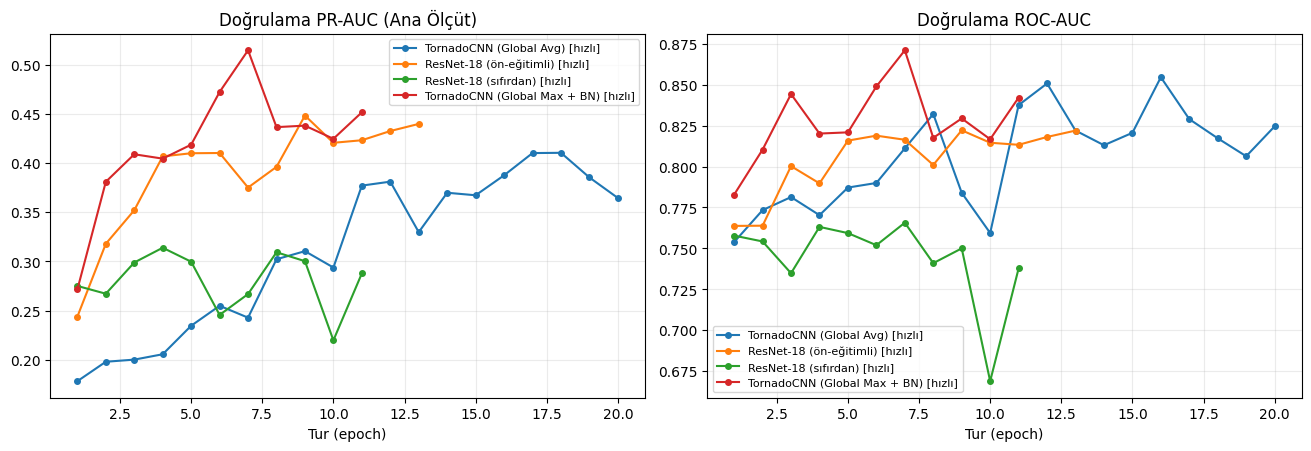

In [4]:
if histories:
    n = len(histories)
    fig, axes = plt.subplots(1, n, figsize=(4.4 * n, 3.6), layout="constrained")
    axes = np.atleast_1d(axes)
    for ax, (folder, (label, hist)) in zip(axes, histories.items()):
        best_ep = best_eps.get(folder) or int(hist.loc[hist["doğrulama PR-AUC"].idxmax(), "tur"])
        ax.plot(hist["tur"], hist["eğitim kaybı"], "o-", ms=4, label="Eğitim")
        ax.plot(hist["tur"], hist["doğrulama kaybı"], "o-", ms=4, label="Doğrulama")
        ax.axvline(best_ep, color="gray", ls="--", lw=1.2, label=f"En iyi ({best_ep})")
        ax.set_title(label, fontsize=10)
        ax.set_xlabel("Tur (epoch)")
        ax.set_ylabel("Kayıp")
        ax.legend(fontsize=8)
    fig.suptitle("Modellerin Eğitim ve Doğrulama Kayıp Eğrileri")
    fig.savefig(RESULTS_DIR / f"learning_curves_loss{SUFFIX}.png", dpi=150)
    plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), layout="constrained")
    for folder, (label, hist) in histories.items():
        axes[0].plot(hist["tur"], hist["doğrulama PR-AUC"], "o-", ms=4, label=label)
        axes[1].plot(hist["tur"], hist["doğrulama AUC"], "o-", ms=4, label=label)
    axes[0].set_title("Doğrulama PR-AUC (Ana Ölçüt)")
    axes[1].set_title("Doğrulama ROC-AUC")
    for ax in axes:
        ax.set_xlabel("Tur (epoch)")
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)
    fig.savefig(RESULTS_DIR / f"learning_curves_auc{SUFFIX}.png", dpi=150)
    plt.show()

## 3. Doğrulama ölçütlerinin karşılaştırması

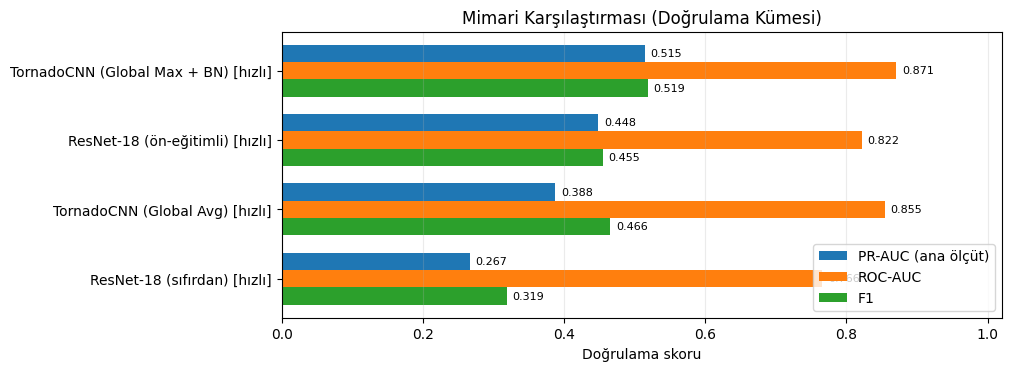

In [5]:
if not table.empty:
    plot_df = table.sort_values("PR-AUC", ascending=True)
    y_pos = np.arange(len(plot_df))
    h = 0.25

    fig, ax = plt.subplots(figsize=(10, max(3.6, 0.9 * len(plot_df))), layout="constrained")
    ax.barh(y_pos + h, plot_df["PR-AUC"], height=h, label="PR-AUC (ana ölçüt)")
    ax.barh(y_pos, plot_df["ROC-AUC"], height=h, label="ROC-AUC")
    ax.barh(y_pos - h, plot_df["F1"], height=h, label="F1")

    for i, (_, r) in enumerate(plot_df.iterrows()):
        ax.text(r["PR-AUC"] + 0.008, y_pos[i] + h, f"{r['PR-AUC']:.3f}", va="center", fontsize=8)
        ax.text(r["ROC-AUC"] + 0.008, y_pos[i], f"{r['ROC-AUC']:.3f}", va="center", fontsize=8)
        ax.text(r["F1"] + 0.008, y_pos[i] - h, f"{r['F1']:.3f}", va="center", fontsize=8)

    ax.set_yticks(y_pos, plot_df["Model"])
    ax.set_xlim(0, 1.02)
    ax.set_xlabel("Doğrulama skoru")
    ax.set_title("Mimari Karşılaştırması (Doğrulama Kümesi)")
    ax.grid(axis="x", alpha=0.25)
    ax.legend(loc="lower right")
    fig.savefig(RESULTS_DIR / f"metrics_comparison{SUFFIX}.png", dpi=150)
    plt.show()